## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Coordenadas de Bilbao
latitude = 43.2540
longitude = -2.9230

url = f"https://api.open-meteo.com/v1/forecast?latitude={latitude}&longitude={longitude}&hourly=temperature_2m&forecast_days=7"

# Realizar la petición
response = requests.get(url)

# Obtener los datos en formato JSON
data = response.json()

In [2]:
data

{'latitude': 43.25,
 'longitude': -2.92,
 'generationtime_ms': 0.06580352783203125,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 14.0,
 'hourly_units': {'time': 'iso8601', 'temperature_2m': '°C'},
 'hourly': {'time': ['2026-11-07T00:00',
   '2026-11-07T01:00',
   '2026-11-07T02:00',
   '2026-11-07T03:00',
   '2026-11-07T04:00',
   '2026-11-07T05:00',
   '2026-11-07T06:00',
   '2026-11-07T07:00',
   '2026-11-07T08:00',
   '2026-11-07T09:00',
   '2026-11-07T10:00',
   '2026-11-07T11:00',
   '2026-11-07T12:00',
   '2026-11-07T13:00',
   '2026-11-07T14:00',
   '2026-11-07T15:00',
   '2026-11-07T16:00',
   '2026-11-07T17:00',
   '2026-11-07T18:00',
   '2026-11-07T19:00',
   '2026-11-07T20:00',
   '2026-11-07T21:00',
   '2026-11-07T22:00',
   '2026-11-07T23:00',
   '2026-11-08T00:00',
   '2026-11-08T01:00',
   '2026-11-08T02:00',
   '2026-11-08T03:00',
   '2026-11-08T04:00',
   '2026-11-08T05:00',
   '2026-11-08T06:00',
   '2026-11-08T07:00',
 

In [ ]:
#Accedemos a las listas
hours = data["hourly"]["time"]

temps = data["hourly"]["temperature_2m"]

In [8]:
#Creamos el dataframe
df = pd.DataFrame({
    "Hora": hours,
    "Temperatura": temps
})

df

,Hora,Temperatura
0,2026-11-07T00:00,11.2
1,2026-11-07T01:00,11.8
2,2026-11-07T02:00,11.9
3,2026-11-07T03:00,11.4
4,2026-11-07T04:00,11.9
...,...,...
163,2026-11-13T19:00,14.0
164,2026-11-13T20:00,13.3
165,2026-11-13T21:00,12.7
166,2026-11-13T22:00,12.3


In [5]:
#Pasamos columna de horas a formato fecha
df["Hora"] = pd.to_datetime(df["Hora"])

In [6]:
df

,Hora,Temperatura
0,2026-11-07 00:00:00,11.2
1,2026-11-07 01:00:00,11.8
2,2026-11-07 02:00:00,11.9
3,2026-11-07 03:00:00,11.4
4,2026-11-07 04:00:00,11.9
...,...,...
163,2026-11-13 19:00:00,14.0
164,2026-11-13 20:00:00,13.3
165,2026-11-13 21:00:00,12.7
166,2026-11-13 22:00:00,12.3


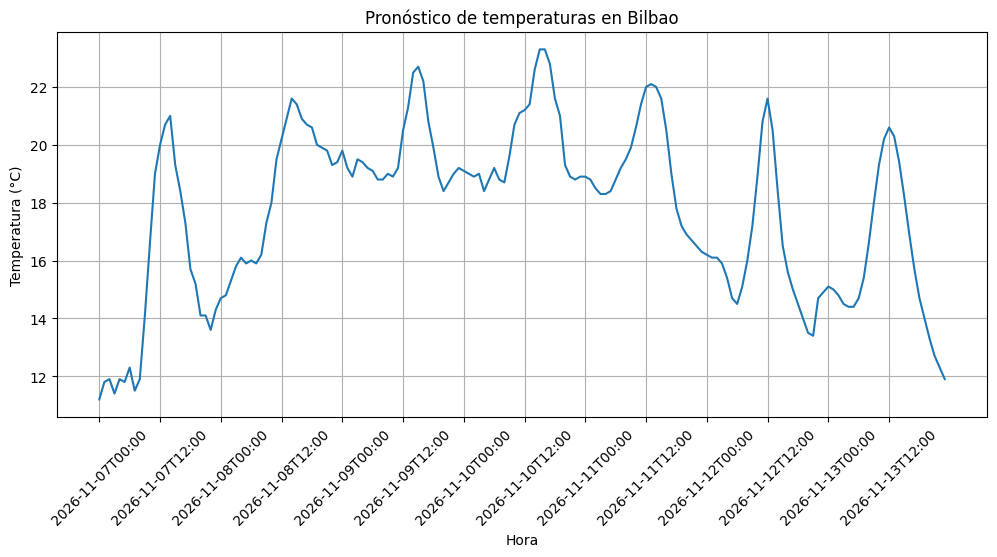

In [10]:
#Gráfico de líneas para ver cómo varía la temperatura con el tiempo
plt.figure(figsize=(12, 5))

plt.plot(df["Hora"], df["Temperatura"])
plt.xticks(df["Hora"][::12], rotation=45)

plt.xlabel("Hora")
plt.ylabel("Temperatura (°C)")
plt.title("Pronóstico de temperaturas en Bilbao")

plt.xticks(rotation=45)
plt.grid()

plt.show()